In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

In [3]:
con = duckdb.connect()
con.read_parquet("../Data/Processed/orders_clean.parquet").create_view("orders");


In [4]:
a = con.execute(""" select *
            from orders """).df()
a.iloc[0:2]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_carrier_before_purchase,flag_customer_before_carrier,...,flag_approval_after_carrier,order_year,order_month,order_day,order_weekday,delivery_duration_days,delivery_delay_days,is_late,approval_hours,carrier_to_customer_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,...,False,2017,10,2,Monday,8.436574,-8,False,0.178333,6.06265
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,...,False,2018,7,24,Tuesday,13.782037,-6,False,30.713889,12.03941


### delivery duration analysis

In [5]:
delivery_time = con.sql(""" 
    select 
        order_id,
        order_purchase_timestamp,
        order_delivered_customer_date,
        delivery_duration_days
    from orders
    where order_status = 'delivered'
        and order_purchase_timestamp is not null
        and order_delivered_customer_date is not null
""").df()


In [6]:
print("orders with their delivery time:")
display(delivery_time.head(10))

orders with their delivery time:


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-09 21:57:05,2017-07-26 10:57:55,16.542245
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-16 13:10:30,2017-05-26 12:55:51,9.989826
7,76c6e866289321a7c93b82b54852dc33,2017-01-23 18:29:09,2017-02-02 14:08:10,9.818762
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-07-29 11:55:02,2017-08-16 17:14:30,18.221852
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-16 19:41:10,2017-05-29 11:18:31,12.650937


In [7]:
#Statistical calculations
cal = delivery_time["delivery_duration_days"].describe().to_frame().round(1)
display(delivery_time["delivery_duration_days"].describe().to_frame().round(1))
print(f"longest delivery time : {cal.loc['max', 'delivery_duration_days']} days")
print(f"shortest delivery time : {cal.loc['min', 'delivery_duration_days']} days")
print(f"average delivery time : {cal.loc['mean', 'delivery_duration_days']} days")

,delivery_duration_days
count,96470.0
mean,12.6
std,9.5
min,0.5
25%,6.8
50%,10.2
75%,15.7
max,209.6


longest delivery time : 209.6 days
shortest delivery time : 0.5 days
average delivery time : 12.6 days


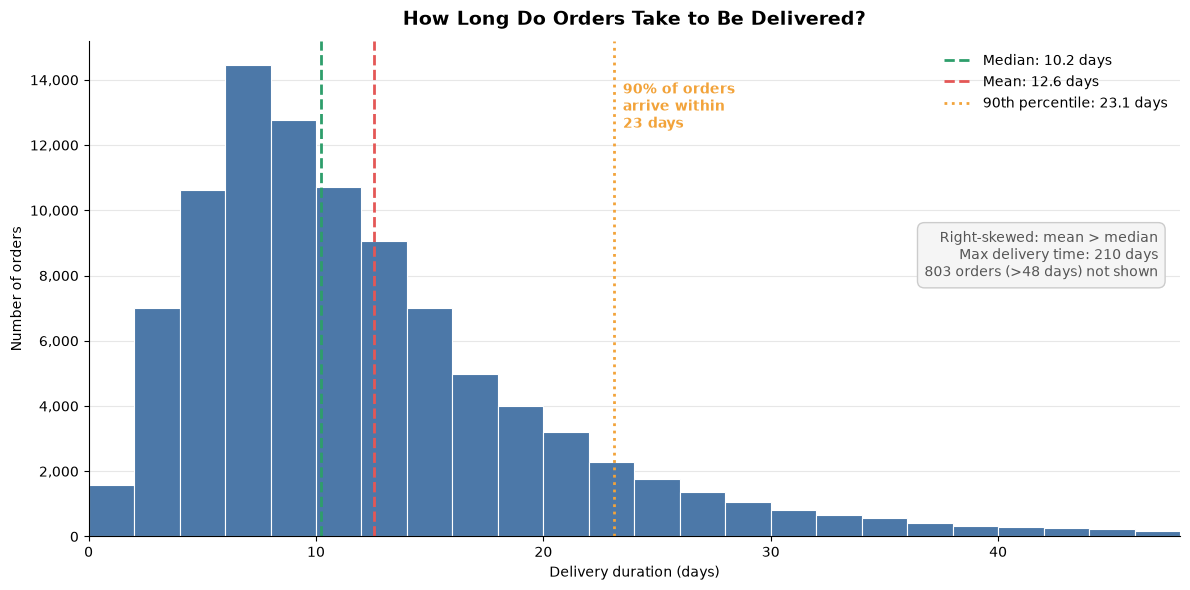

In [8]:
#delivery_time distribution chart
d = delivery_time["delivery_duration_days"]

mean, median = d.mean(), d.median()
p90, p95 = d.quantile(0.90), d.quantile(0.95)

# Zoom to the range that holds ~99% of orders; count the rest separately
cap = np.ceil(d.quantile(0.99) / 2) * 2   # round up to a multiple of the bin width
n_beyond = (d > cap).sum()

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    d[d <= cap],
    bins=np.arange(0, cap + 2, 2),   # 2-day wide bins
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.8,
)

# Reference lines
ax.axvline(median, color="#2E9E6B", linestyle="--", linewidth=2, label=f"Median: {median:.1f} days")
ax.axvline(mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean: {mean:.1f} days")
ax.axvline(p90, color="#F2A33A", linestyle=":", linewidth=2, label=f"90th percentile: {p90:.1f} days")

# Note about the long right tail
ax.text(
    0.98, 0.62,
    f"Right-skewed: mean > median\n"
    f"Max delivery time: {d.max():.0f} days\n"
    f"{n_beyond:,} orders (>{cap:.0f} days) not shown",
    transform=ax.transAxes, ha="right", va="top", fontsize=10, color="#555555",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="#CCCCCC"),
)
ax.text(p90 + 0.4, ax.get_ylim()[1] * 0.92, "90% of orders\narrive within\n23 days",
        color="#F2A33A", fontsize=10, fontweight="bold", va="top")

ax.set_title("How Long Do Orders Take to Be Delivered?", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Delivery duration (days)")
ax.set_ylabel("Number of orders")
ax.set_xlim(0, cap)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(frameon=False, fontsize=10, loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Business Conclusion – Delivery Duration Overview

The analysis of 96,470 successfully delivered orders reveals that the average delivery time is **12.6 days**, while the median delivery time is **10.2 days**. This difference suggests a positively skewed distribution, indicating that a number of orders with unusually long delivery durations increase the overall average.

The standard deviation of **9.5 days** also indicates considerable variability in delivery times, meaning that customers do not experience a consistent delivery duration.

The distribution analysis provides further insights:

- The middle 50% of orders(IQR) were delivered within **6.8 to 15.7 days**.
- **90% of orders** were delivered within approximately 23.1 days.(a useful “worst typical case” number and the 90th percentile is the better number for setting customer expectations)
- A relatively small proportion (about 1%) of orders experienced significantly longer delivery durations ( more than 48 days) with the maximum reaching approximately **210 days**.

The histogram confirms a right-skewed distribution, with most orders concentrated in shorter delivery intervals and a long tail representing delayed deliveries.

**Business Implications:**

Although the majority of customers receive their orders within a relatively reasonable time frame, the existence of extremely long delivery durations indicates potential operational issues affecting a smaller group of orders.

These extreme cases may negatively affect customer experience and should be investigated further.

However, this analysis alone does not identify the causes of long delivery times. Further investigation across different states and delivery periods is necessary to determine whether these delays are concentrated in specific regions or occur more broadly across the business.

**Overall, delivery performance appears reasonably concentrated for most orders, but significant variability and extreme delays remain important areas for operational improvement.**

### Delivery Delay Analysis

In [9]:
delay_days = con.sql(""" 
    select 
        order_id,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        delivery_delay_days
    from orders
    where order_status = 'delivered'
        and order_estimated_delivery_date is not null
        and order_delivered_customer_date is not null
""").df()

#classify orders into early,on-time,late
conditions = [delay_days["delivery_delay_days"] < 0 ,
              delay_days["delivery_delay_days"] == 0 ,
              delay_days["delivery_delay_days"] > 0]

choices = ["early" , "on-time" , "late"]

delay_days["delay_status"] = np.select(conditions ,choices ,default="unknown")

display(delay_days.head(10))

,order_id,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delay_status
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8,early
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6,early
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18,early
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13,early
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10,early
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-26 10:57:55,2017-08-01,-6,early
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-26 12:55:51,2017-06-07,-12,early
7,76c6e866289321a7c93b82b54852dc33,2017-02-02 14:08:10,2017-03-06,-32,early
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-16 17:14:30,2017-08-23,-7,early
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-29 11:18:31,2017-06-07,-9,early


In [10]:
total = delay_days["delay_status"].count()

early   = (delay_days["delay_status"] == "early").sum()
on_time = (delay_days["delay_status"] == "on-time").sum()
late    = (delay_days["delay_status"] == "late").sum()

print(f"number of orders delivered early   : {early}")
print(f"number of orders delivered on-time : {on_time}")
print(f"number of orders delivered late    : {late}")

print(f"\norders delivered early   share : {early   / total * 100:.2f}%")
print(f"orders delivered on-time share : {on_time / total * 100:.2f}%")
print(f"orders delivered late    share : {late    / total * 100:.2f}%")

number of orders delivered early   : 88644
number of orders delivered on-time : 1292
number of orders delivered late    : 6534

orders delivered early   share : 91.89%
orders delivered on-time share : 1.34%
orders delivered late    share : 6.77%


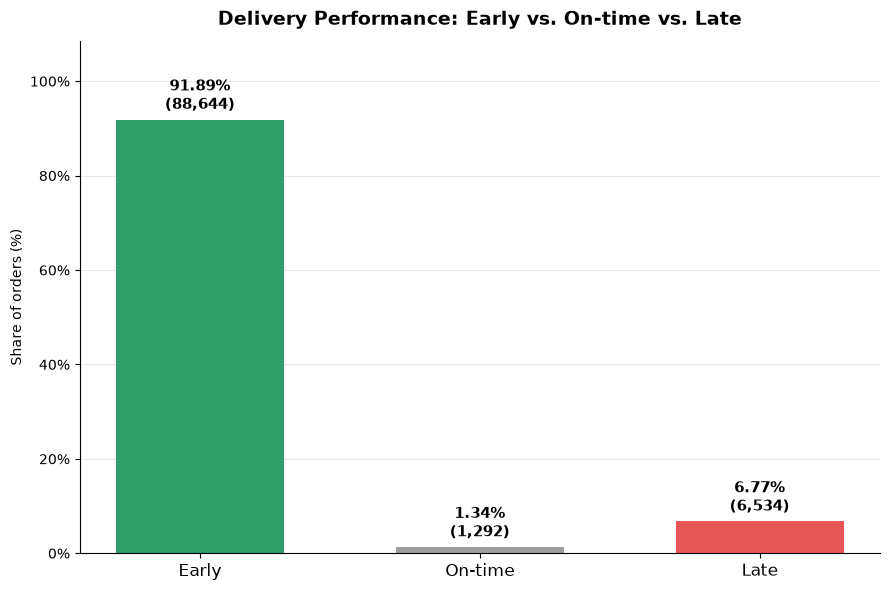

In [11]:

# Count orders in each delivery status
status_counts = (
    delay_days["delay_status"]
    .value_counts()
    .reindex(["early", "on-time", "late"], fill_value=0)
)

total_orders = status_counts.sum()
status_percentages = status_counts / total_orders * 100

# Semantic colors: green = early, gray = on-time, red = late
color_map = {"early": "#2E9E6B", "on-time": "#9E9E9E", "late": "#E45756"}
colors = [color_map[s] for s in status_counts.index]

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    status_counts.index.str.capitalize(),
    status_percentages.values,
    color=colors,
    width=0.6,
)

# Percentage and count above each bar
ax.bar_label(
    bars,
    labels=[f"{p:.2f}%\n({c:,})" for p, c in zip(status_percentages.values, status_counts.values)],
    padding=4,
    fontsize=11,
    fontweight="bold",
)

ax.set_title("Delivery Performance: Early vs. On-time vs. Late", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Share of orders (%)")
ax.set_ylim(0, status_percentages.max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [12]:
#investigate in late delivery
#Group late orders into the days ranges

late = delay_days[delay_days["delay_status"] == "late"]

conditions = [late["delivery_delay_days"].between(1,3) ,
              late["delivery_delay_days"].between(4,7) ,
              late["delivery_delay_days"] > 7] 

choices = ["1-3 days", "4-7 days", "More than 7 days"]

late["delay_group"] = np.select(conditions,choices,default="unknown")


print(f"average and median delay days for late orders: {late["delivery_delay_days"].mean():.1f} days(average) and {late["delivery_delay_days"].median()} days(median)")

for group in choices:
    n = (late["delay_group"] == group).sum()
    print(f"orders late by {group:<18}: {n:>6}  ({n / len(late) * 100:.2f}%)")

average and median delay days for late orders: 10.6 days(average) and 7.0 days(median)
orders late by 1-3 days          :   1870  (28.62%)
orders late by 4-7 days          :   1802  (27.58%)
orders late by More than 7 days  :   2862  (43.80%)


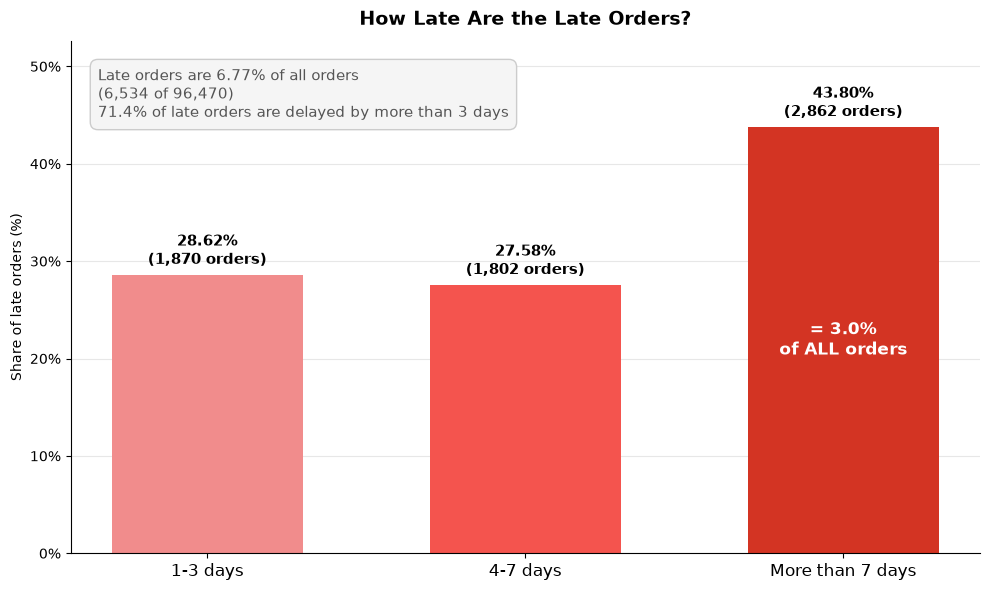

In [ ]:

group_order = ["1-3 days", "4-7 days", "More than 7 days"]

group_counts = (
    late["delay_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
)
group_percentages = group_counts / group_counts.sum() * 100

# Context numbers: late orders relative to ALL orders
total_orders = len(delay_days)               # all orders (early + on-time + late); adjust if your variable differs
late_total = group_counts.sum()
late_of_all = late_total / total_orders * 100
severe_count = group_counts["More than 7 days"]
severe_of_all = severe_count / total_orders * 100
over_3 = group_percentages[["4-7 days", "More than 7 days"]].sum()

colors = ["#F18C8C", "#F4544E", "#D33423"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(group_order, group_percentages.values, color=colors, width=0.6)

ax.bar_label(
    bars,
    labels=[f"{p:.2f}%\n({c:,} orders)" for p, c in zip(group_percentages.values, group_counts.values)],
    padding=4,
    fontsize=11,
    fontweight="bold",
)

# Inside the worst bar: its share of ALL orders
worst = bars[2]
ax.text(
    worst.get_x() + worst.get_width() / 2,
    worst.get_height() / 2,
    f"= {severe_of_all:.1f}%\nof ALL orders",
    ha="center", va="center", fontsize=12, fontweight="bold", color="white",
)

# Callout with the key context
ax.text(
    0.03, 0.95,
    f"Late orders are {late_of_all:.2f}% of all orders\n"
    f"({late_total:,} of {total_orders:,})\n"
    f"{over_3:.1f}% of late orders are delayed by more than 3 days",
    transform=ax.transAxes, ha="left", va="top", fontsize=11, color="#555555",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="#CCCCCC"),
)

ax.set_title("How Late Are the Late Orders?", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Share of late orders (%)")
ax.set_ylim(0, group_percentages.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Business Conclusion – Delivery Delays and Delivery Performance

The analysis of 96,470 delivered orders reveals that Olist performs relatively well in meeting or exceeding its estimated delivery dates.

- **91.89%** of orders (88,644 orders) were delivered earlier than estimated.
- **1.34%** (1,292 orders) were delivered exactly on the estimated date.
- **6.77%** (6,534 orders) were delivered later than expected.

Although the overall late delivery rate is relatively low, further investigation reveals that a considerable proportion of late orders experience significant delays.

Among the 6,534 late orders:

- 28.62% were delayed by 1–3 days.
- 27.58% were delayed by 4–7 days.
- 43.80% were delayed by more than 7 days.

The average delay among late orders is **10.6 days**, while the median is **7 days**, suggesting that some orders experience considerably longer delays and increase the average.The 7-day median provides a better picture of the midpoint of this statistical population.

**Business Implications:**

Despite the high proportion of early deliveries, the number and severity of late deliveries remain important operational concerns.

In particular, the 2,862 orders delayed by more than seven days represent approximately **2.97% of all delivered orders** and deserve further investigation.

Olist should focus on identifying the operational factors associated with these significant delays rather than evaluating delivery performance solely through the overall late delivery rate.

Additionally, the very high percentage of early deliveries may indicate that estimated delivery dates are relatively conservative. Reviewing the accuracy of delivery time estimates could help improve delivery planning and provide customers with more reliable expectations.

**Overall, Olist delivers most orders earlier than estimated, but a smaller group of customers experiences substantial delivery delays. Reducing these severe delays and improving delivery time estimation should be important priorities for operational improvement.**